# ESS11 — Les valeurs humaines : structure et typologie

**Source des données** : [European Social Survey (ESS), Round 11](https://ess.sikt.no/en/series/50ebb530-c72e-4002-a7bf-5581e3fdfe21) — fichier `ESS11MD`, sous-ensemble préparé dans `ESS_start.csv` (étape 1).

**Étape 4 — Analyse factorielle des 21 valeurs de Schwartz, puis clustering**

Même démarche que pour la confiance :
1. matrice de corrélations des 21 items (PVQ) ;
2. factorisabilité (KMO, Bartlett) et choix du nombre de facteurs (scree / Kaiser) ;
3. EFA avec rotation oblique (*oblimin*) et sauvegarde des scores dans `ESS_start.csv` ;
4. **clustering mixte** : k-means en ~100 micro-classes, puis classification ascendante hiérarchique (**Ward**) sur les centroïdes, dendrogramme et affectation finale ;
5. bonus : bonheur moyen par cluster.

⚠️ Les items PVQ sont codés 1 = « tout à fait comme moi » … 6 = « pas du tout comme moi ». On **inverse** (7 − x) pour que haut = forte adhésion à la valeur.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from sklearn.cluster import KMeans

df = pd.read_csv("ESS_start.csv")

val_items = {
    "ipcrtiva": "créativité",        "impricha": "richesse",
    "ipeqopta": "égalité",           "ipshabta": "montrer ses capacités",
    "impsafea": "sécurité",          "impdiffa": "nouveauté",
    "ipfrulea": "obéir aux règles",  "ipudrsta": "comprendre autrui",
    "ipmodsta": "modestie",          "ipgdtima": "bon temps",
    "impfreea": "liberté",           "iphlppla": "aider autrui",
    "ipsucesa": "réussite",          "ipstrgva": "État fort",
    "ipadvnta": "aventure",          "ipbhprpa": "se comporter bien",
    "iprspota": "respect/admiration","iplylfra": "loyauté",
    "impenva":  "environnement",     "imptrada": "tradition",
    "impfuna":  "plaisir",
}
vals = list(val_items.keys())

# Inversion : haut = forte adhésion
V = (7 - df[vals]).dropna()
print(f"Échantillon complet : {len(df):,} — après suppression des NA sur les valeurs : {len(V):,}")

Échantillon complet : 46,162 — après suppression des NA sur les valeurs : 42,814


## 1. Matrice de corrélations

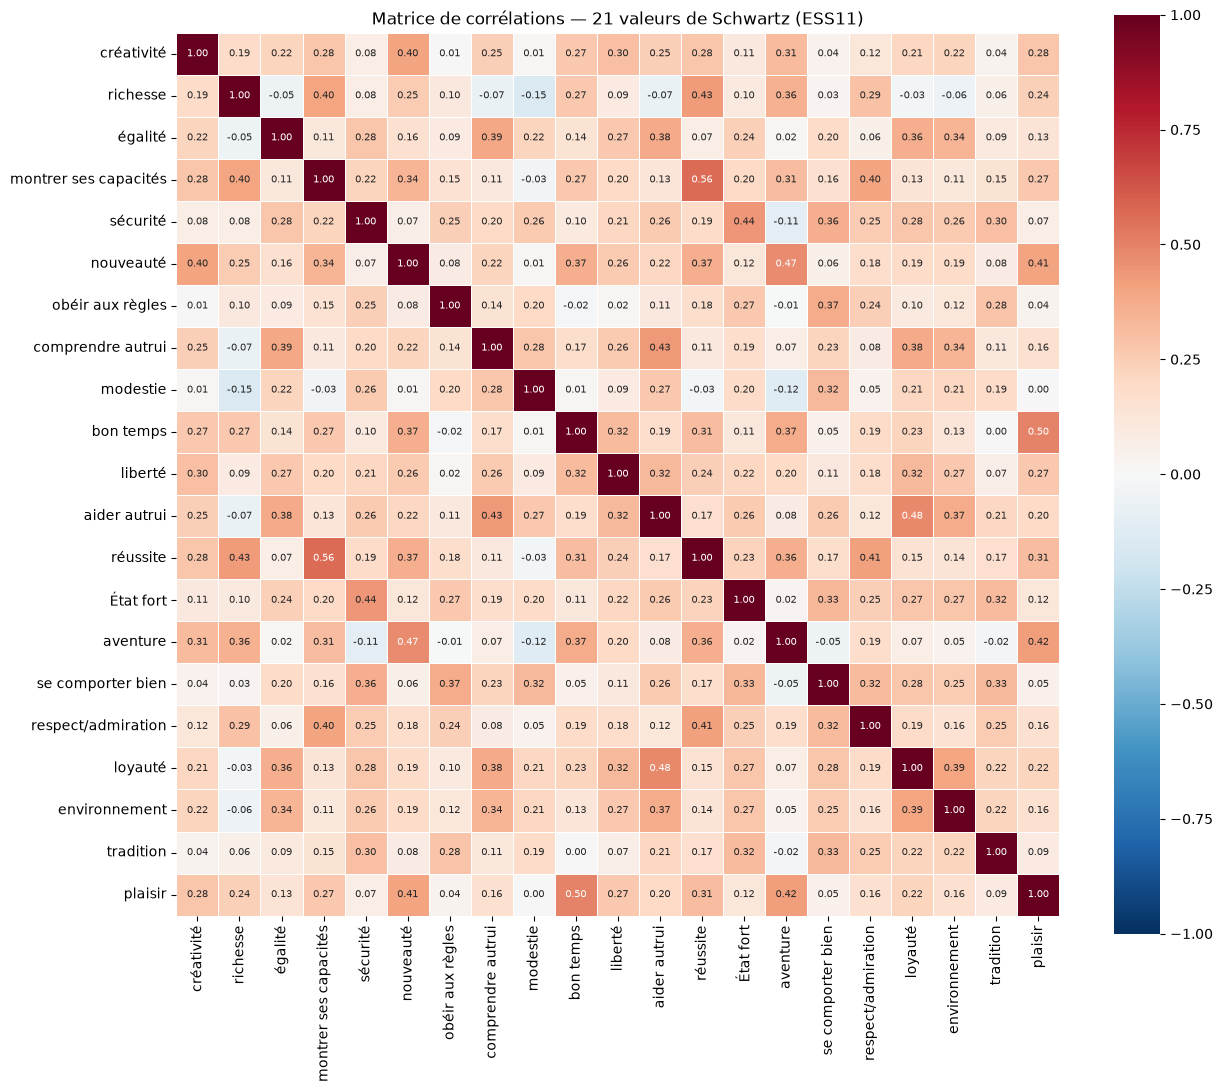

In [11]:
corr = V.corr()
labels = [val_items[v] for v in corr.columns]

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            xticklabels=labels, yticklabels=labels,
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Matrice de corrélations — 21 valeurs de Schwartz (ESS11)")
plt.tight_layout()
plt.show()

## 2. Factorisabilité et nombre de facteurs

c:\Users\33623\Documents\_Classes\master101\master_101_Nov2026\.venv-2\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Bartlett : chi2 = 238,137, p = 0
KMO global : 0.887

Valeurs propres : [4.99 2.77 1.91 0.96 0.9  0.83 0.79 0.7  0.69 0.65 0.62 0.6  0.59 0.58
 0.55 0.53 0.52 0.49 0.48 0.44 0.41]
Facteurs avec valeur propre > 1 (Kaiser) : 3


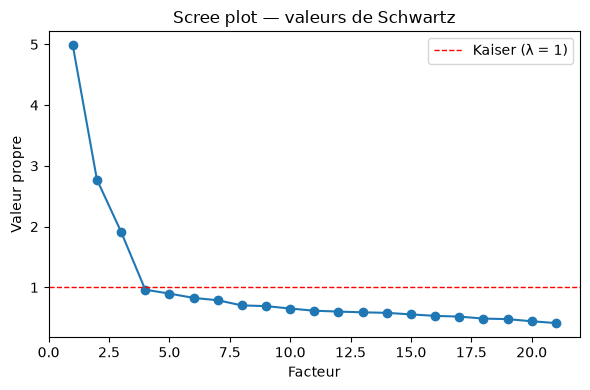

In [12]:
chi2, p_bartlett = calculate_bartlett_sphericity(V)
kmo_per_item, kmo_global = calculate_kmo(V)
print(f"Bartlett : chi2 = {chi2:,.0f}, p = {p_bartlett:.3g}")
print(f"KMO global : {kmo_global:.3f}")

fa_expl = FactorAnalyzer(n_factors=len(vals), rotation=None)
fa_expl.fit(V)
eigenvalues, _ = fa_expl.get_eigenvalues()
print("\nValeurs propres :", np.round(eigenvalues, 2))
print(f"Facteurs avec valeur propre > 1 (Kaiser) : {(eigenvalues > 1).sum()}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(eigenvalues) + 1), eigenvalues, "o-")
ax.axhline(1, color="red", ls="--", lw=1, label="Kaiser (λ = 1)")
ax.set_xlabel("Facteur")
ax.set_ylabel("Valeur propre")
ax.set_title("Scree plot — valeurs de Schwartz")
ax.legend()
plt.tight_layout()
plt.show()

## 3. EFA avec rotation oblique (oblimin)

On retient **4 facteurs**, en cohérence avec les dimensions d'ordre supérieur de Schwartz. L'interprétation, d'après les items dominants (heatmap ci-dessous) :

| Facteur | Interprétation | Items dominants |
|---|---|---|
| **F1** | **Dépassement de soi** (*self-transcendence*) | aider autrui (.63), égalité (.62), loyauté (.61), comprendre autrui (.56), environnement (.53) |
| **F2** | **Affirmation de soi** (*self-enhancement*) | montrer ses capacités (.66), réussite (.63), richesse (.53), respect/admiration (.49) |
| **F3** | **Ouverture au changement** (*openness to change*) | aventure (.69), nouveauté (.58), plaisir (.55), bon temps (.43) — sécurité en négatif (−.31) |
| **F4** | **Conservation / continuité** | obéir aux règles (.61), se comporter bien (.61), tradition (.46), modestie (.39) |

Les corrélations entre facteurs (φ) reproduisent le cercle de Schwartz : les dimensions adjacentes sont corrélées positivement (F2-F4 = .46, F1-F3 = .41), les dimensions opposées faiblement ou négativement (F2-F3 = −.15).

![Cercle des valeurs de Schwartz](https://i0.wp.com/i2insights.org/wp-content/uploads/2022/03/schwartz_theory-of-basic-values_dynamic-relations.jpg?resize=625%2C593&ssl=1)

*Relations dynamiques entre les dix valeurs de base (adapté de Schwartz, 2012). Source : [Schwartz, « Understanding values », Integration and Implementation Insights, 2022](https://i2insights.org/2022/05/10/schwartz-theory-of-basic-values/).*

c:\Users\33623\Documents\_Classes\master101\master_101_Nov2026\.venv-2\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Variance expliquée :
                   F1     F2     F3     F4
SS loadings     2.554  1.744  1.621  1.400
Prop. variance  0.122  0.083  0.077  0.067
Cumul           0.122  0.205  0.282  0.349

Corrélation entre facteurs (phi) :
       F1     F2     F3     F4
F1  1.000  0.188  0.405  0.191
F2  0.188  1.000 -0.146  0.462
F3  0.405 -0.146  1.000  0.286
F4  0.191  0.462  0.286  1.000


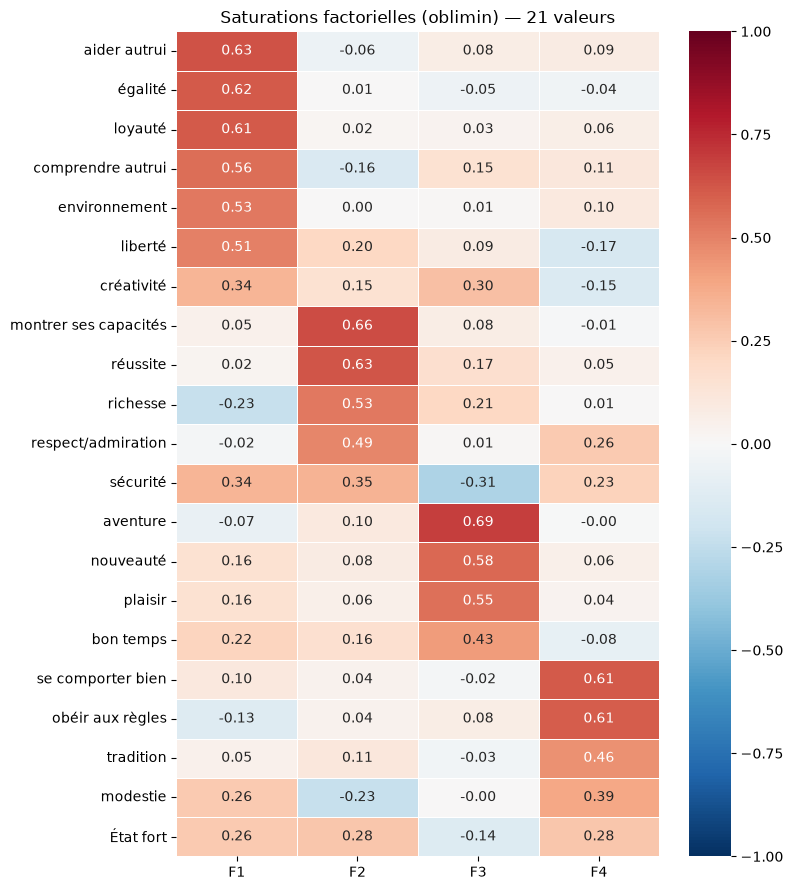

In [13]:
N_FACTORS = 4
fa = FactorAnalyzer(n_factors=N_FACTORS, rotation="oblimin", method="minres")
fa.fit(V)

fcols = [f"F{i+1}" for i in range(N_FACTORS)]
loadings = pd.DataFrame(fa.loadings_, index=vals, columns=fcols)

# Regroupement des items par facteur dominant, triés par saturation décroissante
dominant = loadings.abs().idxmax(axis=1)
sat_max = loadings.abs().max(axis=1)
ordre = (pd.DataFrame({"dom": dominant, "sat": sat_max})
           .sort_values(["dom", "sat"], ascending=[True, False]).index)
loadings = loadings.loc[ordre].round(3)
loadings.index = [val_items[v] for v in ordre]  # traduction seule

var_exp = pd.DataFrame(fa.get_factor_variance(),
                       index=["SS loadings", "Prop. variance", "Cumul"],
                       columns=fcols).round(3)
print("Variance expliquée :")
print(var_exp)

phi = pd.DataFrame(fa.phi_, index=fcols, columns=fcols).round(3)
print("\nCorrélation entre facteurs (phi) :")
print(phi)

fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Saturations factorielles (oblimin) — 21 valeurs")
plt.tight_layout()
plt.show()

## 4. Scores factoriels et sauvegarde

In [14]:
# Nommage des facteurs d'après l'item le plus saturant (à ajuster après lecture des saturations)
scores = pd.DataFrame(fa.transform(V), index=V.index, columns=fcols)

score_names = {f: f"val_{f}" for f in fcols}
scores = scores.rename(columns=score_names)

for c in scores.columns:
    df[c] = scores[c]

df.to_csv("ESS_start.csv", index=False)
print(f"ESS_start.csv mis à jour : {df.shape[1]} colonnes "
      f"(scores valeurs pour {len(scores):,} répondants)")
scores.describe().round(3)

c:\Users\33623\Documents\_Classes\master101\master_101_Nov2026\.venv-2\Lib\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


ESS_start.csv mis à jour : 59 colonnes (scores valeurs pour 42,814 répondants)


,val_F1,val_F2,val_F3,val_F4
count,42814.000,42814.000,42814.000,42814.000
mean,-0.000,-0.000,-0.000,-0.000
std,0.903,0.887,0.880,0.852
min,-5.125,-2.954,-3.025,-3.674
25%,-0.504,-0.634,-0.595,-0.546
50%,0.102,0.024,0.033,0.066
75%,0.624,0.636,0.626,0.606
max,1.988,2.550,2.727,2.474


## 5. Clustering mixte : k-means (100 micro-classes) + CAH de Ward

Méthode classique pour les gros échantillons :
1. **k-means avec ~100 clusters** : on résume les 40 000+ répondants en 100 micro-classes homogènes (réduction du bruit et du coût de calcul) ;
2. **CAH (méthode de Ward)** sur les centroïdes des micro-classes, pondérés par leurs effectifs ;
3. lecture du **dendrogramme** pour choisir le nombre final de groupes, puis affectation de chaque répondant via sa micro-classe.

**Lecture des profils des 6 clusters** (moyennes des scores factoriels, heatmap plus bas) — en utilisant l'interprétation des facteurs (F1 = dépassement de soi, F2 = affirmation de soi, F3 = ouverture, F4 = conservation) :

| Cluster | Poids | Profil | Interprétation |
|---|---|---|---|
| **1** | ≈ 13 % | F2 et F4 très négatifs | **Détachés anticonformistes** : rejettent autant l'affirmation de soi que la conformité |
| **2** | ≈ 10 % | F3 très négatif, F1-F2 faibles | **Repliés prudents** : fermés à la nouveauté, peu engagés, attachés à la seule prudence |
| **3** | ≈ 9 % | F1 très négatif, F4 négatif | **Individualistes désengagés** : rejet marqué des valeurs altruistes et de la tradition |
| **4** | ≈ 23 % | F1 et F4 positifs, F3 négatif | **Conservateurs altruistes** : tournés vers les autres et la continuité, fermés à la nouveauté |
| **5** | ≈ 15 % | tous les scores fortement positifs | **Hyper-engagés** : endossent très fortement l'ensemble des valeurs |
| **6** | ≈ 30 % | F2 et F3 positifs, F4 légèrement négatif | **Ambitieux ouverts** : réussite et nouveauté, peu conformistes |

100 micro-classes : effectifs de 117 à 888 répondants


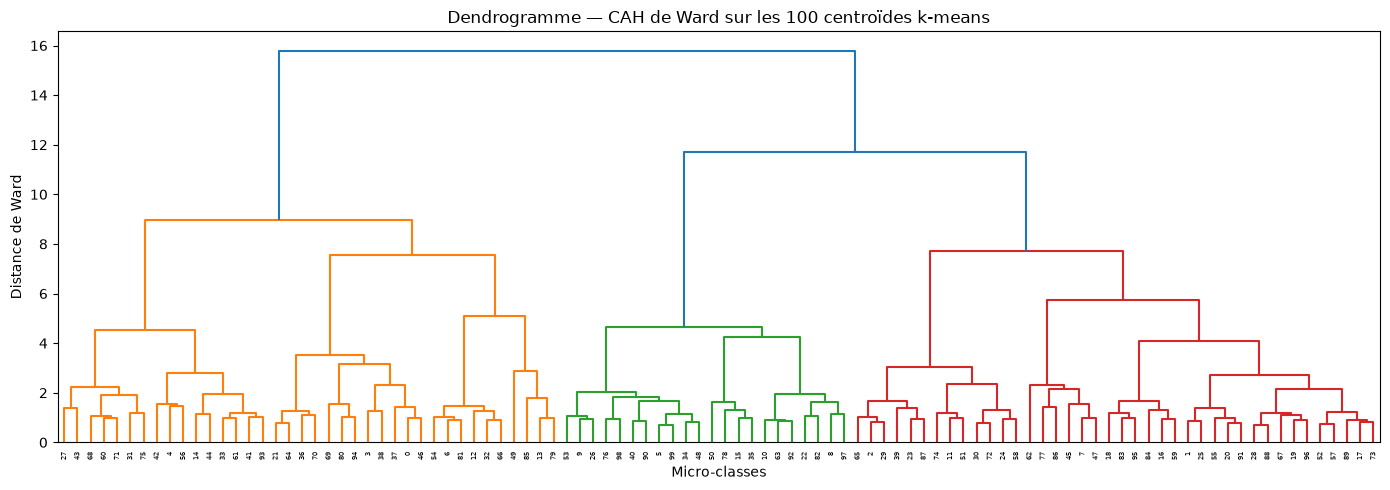

Distances des 10 dernières fusions : [ 4.25  4.55  4.64  5.12  5.73  7.57  7.73  8.95 11.69 15.78]


In [15]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

S = scores.copy()
S = (S - S.mean()) / S.std(ddof=1)  # standardisation

# Étape 1 : k-means en 100 micro-classes
N_MICRO = 100
km_micro = KMeans(n_clusters=N_MICRO, n_init=10, random_state=42).fit(S)
micro_labels = km_micro.labels_
centroides = km_micro.cluster_centers_
effectifs = np.bincount(micro_labels, minlength=N_MICRO)
print(f"{N_MICRO} micro-classes : effectifs de {effectifs.min()} à {effectifs.max()} répondants")

# Étape 2 : CAH de Ward sur les centroïdes (pondérés par les effectifs via répétition implicite)
Z = linkage(centroides, method="ward")

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, ax=ax, color_threshold=0.7 * Z[:, 2].max())
ax.set_title("Dendrogramme — CAH de Ward sur les 100 centroïdes k-means")
ax.set_xlabel("Micro-classes")
ax.set_ylabel("Distance de Ward")
plt.tight_layout()
plt.show()

# Sauts de fusion pour guider le choix du nombre de groupes
fusions = Z[-10:, 2]
print("Distances des 10 dernières fusions :", np.round(fusions, 2))

Effectifs par cluster :
  1 - Détachés anticonformistes     5,401 (12.6%)
  2 - Repliés prudents              4,244 (9.9%)
  3 - Individualistes désengagés    3,866 (9.0%)
  4 - Conservateurs altruistes      9,852 (23.0%)
  5 - Hyper-engagés                 6,387 (14.9%)
  6 - Ambitieux ouverts            13,064 (30.5%)


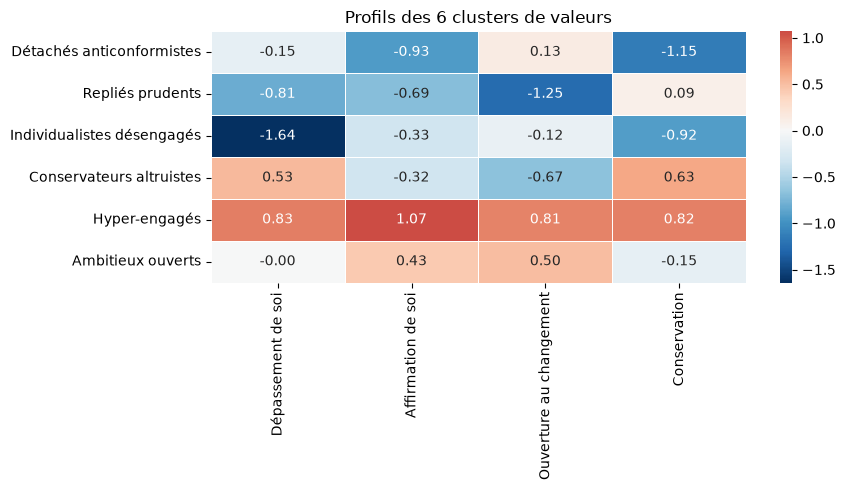

In [18]:
# Étape 3 : coupure du dendrogramme et affectation des répondants
K = 6  # choix retenu au vu du dendrogramme et des sauts de fusion
macro_of_micro = fcluster(Z, t=K, criterion="maxclust")

df["val_cluster"] = pd.Series(macro_of_micro[micro_labels], index=S.index)

df.to_csv("ESS_start.csv", index=False)

# Interprétations : facteurs et clusters
facteur_labels = {
    "val_F1": "Dépassement de soi",
    "val_F2": "Affirmation de soi",
    "val_F3": "Ouverture au changement",
    "val_F4": "Conservation",
}
cluster_labels = {
    1: "Détachés anticonformistes",
    2: "Repliés prudents",
    3: "Individualistes désengagés",
    4: "Conservateurs altruistes",
    5: "Hyper-engagés",
    6: "Ambitieux ouverts",
}

tailles = df["val_cluster"].value_counts().sort_index()
print("Effectifs par cluster :")
for num, n in tailles.items():
    print(f"  {int(num)} - {cluster_labels[int(num)]:<28} {n:>6,} ({n / tailles.sum():.1%})")

# Profils : moyenne des scores factoriels par cluster, avec les interprétations
profils = df.groupby("val_cluster")[list(scores.columns)].mean().round(2)
profils = profils.rename(columns=facteur_labels)
profils.index = [cluster_labels[int(num)] for num in profils.index]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(profils, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, ax=ax)
ax.set_title(f"Profils des {K} clusters de valeurs")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Bonus : bonheur et clusters de valeurs

Les **Repliés prudents** (≈ −0,37) et les **Individualistes désengagés** (≈ −0,27) sont nettement moins heureux que la moyenne ; à l'inverse, les **Hyper-engagés** (≈ +0,23) et les **Détachés anticonformistes** (≈ +0,14) affichent le bien-être le plus élevé. L'endossement actif de valeurs — quelles qu'elles soient — accompagne le bien-être, tandis que le repli et le désengagement vont de pair avec un bonheur plus faible.

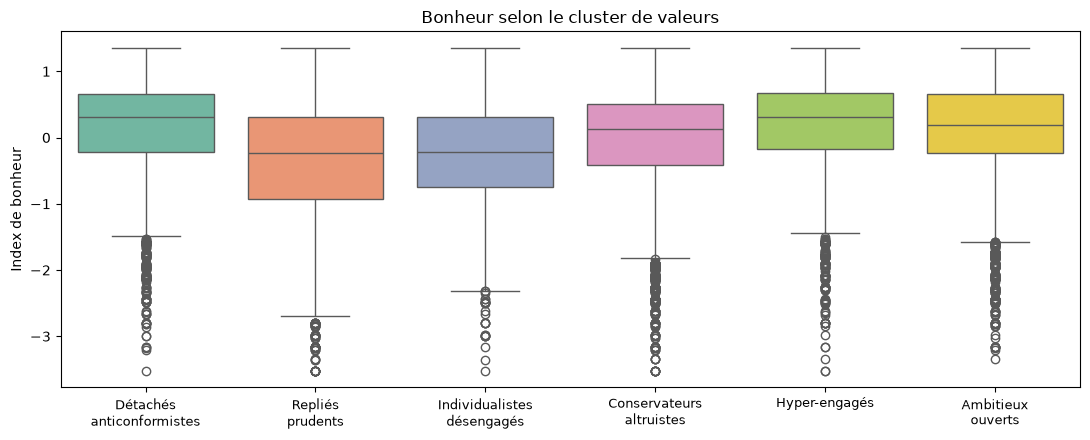

                             mean    std  count
Détachés anticonformistes   0.143  0.724   5370
Repliés prudents           -0.369  0.893   4196
Individualistes désengagés -0.268  0.750   3825
Conservateurs altruistes   -0.031  0.800   9772
Hyper-engagés               0.227  0.699   6332
Ambitieux ouverts           0.104  0.707  12964


In [19]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=df, x="val_cluster", y="bonheur_index", hue="val_cluster",
            palette="Set2", legend=False, ax=ax)
ax.set_xticks(range(K))
ax.set_xticklabels([cluster_labels[k].replace(" ", "\n") for k in sorted(cluster_labels)], fontsize=9)
ax.set_xlabel("")
ax.set_ylabel("Index de bonheur")
ax.set_title("Bonheur selon le cluster de valeurs")
plt.tight_layout()
plt.show()

stats = df.groupby("val_cluster")["bonheur_index"].agg(["mean", "std", "count"]).round(3)
stats.index = [cluster_labels[int(num)] for num in stats.index]
print(stats)